In [ ]:
import pandas as pd
df=pd.read_csv("/content/K_Means_flo_data_20k.csv")
df.head()

,master_id,order_channel,last_order_channel,first_order_date,last_order_date,last_order_date_online,last_order_date_offline,order_num_total_ever_online,order_num_total_ever_offline,customer_value_total_ever_offline,customer_value_total_ever_online,interested_in_categories_12
0,cc294636-19f0-11eb-8d74-000d3a38a36f,Android App,Offline,2020-10-30,2021-02-26,2021-02-21,2021-02-26,4.0,1.0,139.99,799.38,[KADIN]
1,f431bd5a-ab7b-11e9-a2fc-000d3a38a36f,Android App,Mobile,2017-02-08,2021-02-16,2021-02-16,2020-01-10,19.0,2.0,159.97,1853.58,"[ERKEK, COCUK, KADIN, AKTIFSPOR]"
2,69b69676-1a40-11ea-941b-000d3a38a36f,Android App,Android App,2019-11-27,2020-11-27,2020-11-27,2019-12-01,3.0,2.0,189.97,395.35,"[ERKEK, KADIN]"
3,1854e56c-491f-11eb-806e-000d3a38a36f,Android App,Android App,2021-01-06,2021-01-17,2021-01-17,2021-01-06,1.0,1.0,39.99,81.98,"[AKTIFCOCUK, COCUK]"
4,d6ea1074-f1f5-11e9-9346-000d3a38a36f,Desktop,Desktop,2019-08-03,2021-03-07,2021-03-07,2019-08-03,1.0,1.0,49.99,159.99,[AKTIFSPOR]


In [ ]:
df.shape

(19945, 12)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19945 entries, 0 to 19944
Data columns (total 12 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   master_id                          19945 non-null  object 
 1   order_channel                      19945 non-null  object 
 2   last_order_channel                 19945 non-null  object 
 3   first_order_date                   19945 non-null  object 
 4   last_order_date                    19945 non-null  object 
 5   last_order_date_online             19945 non-null  object 
 6   last_order_date_offline            19945 non-null  object 
 7   order_num_total_ever_online        19945 non-null  float64
 8   order_num_total_ever_offline       19945 non-null  float64
 9   customer_value_total_ever_offline  19945 non-null  float64
 10  customer_value_total_ever_online   19945 non-null  float64
 11  interested_in_categories_12        19945 non-null  obj

In [ ]:
df1=df.copy()
df1['tenure']=(pd.to_datetime('today')-pd.to_datetime(df1['first_order_date'])).dt.days
df1['recency']=(pd.to_datetime('today')-pd.to_datetime(df1['last_order_date'])).dt.days
df1['frequency']=df1['order_num_total_ever_online']+df1['order_num_total_ever_offline']
df1['monetary']=df1['customer_value_total_ever_online'] + df1['customer_value_total_ever_offline']
df1["order_num_total"] = df1["order_num_total_ever_online"] + df1["order_num_total_ever_offline"]
df1["customer_value_total"] = df1["customer_value_total_ever_offline"] + df1["customer_value_total_ever_online"]

In [ ]:
df1.columns

Index(['master_id', 'order_channel', 'last_order_channel', 'first_order_date',
       'last_order_date', 'last_order_date_online', 'last_order_date_offline',
       'order_num_total_ever_online', 'order_num_total_ever_offline',
       'customer_value_total_ever_offline', 'customer_value_total_ever_online',
       'interested_in_categories_12', 'tenure', 'recency', 'frequency',
       'monetary', 'order_num_total', 'customer_value_total'],
      dtype='object')

In [ ]:
master_dict = {value: i+1 for i, value in enumerate(df1['master_id'].unique())}
print(master_dict)

{'cc294636-19f0-11eb-8d74-000d3a38a36f': 1, 'f431bd5a-ab7b-11e9-a2fc-000d3a38a36f': 2, '69b69676-1a40-11ea-941b-000d3a38a36f': 3, '1854e56c-491f-11eb-806e-000d3a38a36f': 4, 'd6ea1074-f1f5-11e9-9346-000d3a38a36f': 5, 'e585280e-aae1-11e9-a2fc-000d3a38a36f': 6, 'c445e4ee-6242-11ea-9d1a-000d3a38a36f': 7, '3f1b4dc8-8a7d-11ea-8ec0-000d3a38a36f': 8, 'cfbda69e-5b4f-11ea-aca7-000d3a38a36f': 9, '1143f032-440d-11ea-8b43-000d3a38a36f': 10, 'ae608ece-c9d8-11ea-a31e-000d3a38a36f': 11, 'c2e15af2-9eed-11e9-9897-000d3a38a36f': 12, '2854f11a-0185-11ea-a5e8-000d3a38a36f': 13, 'ec6c382a-3e97-11ea-a823-000d3a38a36f': 14, '241f0ad0-afb5-11e9-9757-000d3a38a36f': 15, '13ed97a4-b167-11e9-89fa-000d3a38a36f': 16, 'd9b77226-a509-11e9-a2fc-000d3a38a36f': 17, 'efb82ba4-aaba-11e9-a2fc-000d3a38a36f': 18, '1ee5ae66-7237-11eb-aa44-000d3a38a36f': 19, '2730793e-3908-11ea-85d6-000d3a38a36f': 20, '4da5c2ba-403b-11ea-aa6b-000d3a38a36f': 21, '7b289956-d691-11e9-93bc-000d3a38a36f': 22, '1a9b39d8-40ac-11ea-9be8-000d3a38a36f': 

In [ ]:
df1['master_id'] = df1['master_id'].map(master_dict)

In [ ]:
cat_cols=['order_channel', 'last_order_channel']
num_cols=['order_num_total_ever_online', 'order_num_total_ever_offline',
       'customer_value_total_ever_offline', 'customer_value_total_ever_online',
       'tenure', 'recency', 'frequency',
       'monetary', 'order_num_total', 'customer_value_total']

In [ ]:
df2=df1.drop(columns=['first_order_date',
       'last_order_date', 'last_order_date_online', 'last_order_date_offline'])
df2.head()

,master_id,order_channel,last_order_channel,order_num_total_ever_online,order_num_total_ever_offline,customer_value_total_ever_offline,customer_value_total_ever_online,interested_in_categories_12,tenure,recency,frequency,monetary,order_num_total,customer_value_total
0,1,Android App,Offline,4.0,1.0,139.99,799.38,[KADIN],2076,1957,5.0,939.37,5.0,939.37
1,2,Android App,Mobile,19.0,2.0,159.97,1853.58,"[ERKEK, COCUK, KADIN, AKTIFSPOR]",3436,1967,21.0,2013.55,21.0,2013.55
2,3,Android App,Android App,3.0,2.0,189.97,395.35,"[ERKEK, KADIN]",2414,2048,5.0,585.32,5.0,585.32
3,4,Android App,Android App,1.0,1.0,39.99,81.98,"[AKTIFCOCUK, COCUK]",2008,1997,2.0,121.97,2.0,121.97
4,5,Desktop,Desktop,1.0,1.0,49.99,159.99,[AKTIFSPOR],2530,1948,2.0,209.98,2.0,209.98


In [ ]:
print(df2["order_channel"].value_counts())
print(df2["last_order_channel"].value_counts())

order_channel
Android App    9495
Mobile         4882
Ios App        2833
Desktop        2735
Name: count, dtype: int64
last_order_channel
Android App    6783
Offline        6608
Mobile         3172
Ios App        1696
Desktop        1686
Name: count, dtype: int64


In [ ]:
df2=pd.get_dummies(df2,columns=cat_cols,dtype=int)
df2.head()

,master_id,order_num_total_ever_online,order_num_total_ever_offline,customer_value_total_ever_offline,customer_value_total_ever_online,interested_in_categories_12,tenure,recency,frequency,monetary,...,customer_value_total,order_channel_Android App,order_channel_Desktop,order_channel_Ios App,order_channel_Mobile,last_order_channel_Android App,last_order_channel_Desktop,last_order_channel_Ios App,last_order_channel_Mobile,last_order_channel_Offline
0,1,4.0,1.0,139.99,799.38,[KADIN],2076,1957,5.0,939.37,...,939.37,1,0,0,0,0,0,0,0,1
1,2,19.0,2.0,159.97,1853.58,"[ERKEK, COCUK, KADIN, AKTIFSPOR]",3436,1967,21.0,2013.55,...,2013.55,1,0,0,0,0,0,0,1,0
2,3,3.0,2.0,189.97,395.35,"[ERKEK, KADIN]",2414,2048,5.0,585.32,...,585.32,1,0,0,0,1,0,0,0,0
3,4,1.0,1.0,39.99,81.98,"[AKTIFCOCUK, COCUK]",2008,1997,2.0,121.97,...,121.97,1,0,0,0,1,0,0,0,0
4,5,1.0,1.0,49.99,159.99,[AKTIFSPOR],2530,1948,2.0,209.98,...,209.98,0,1,0,0,0,1,0,0,0


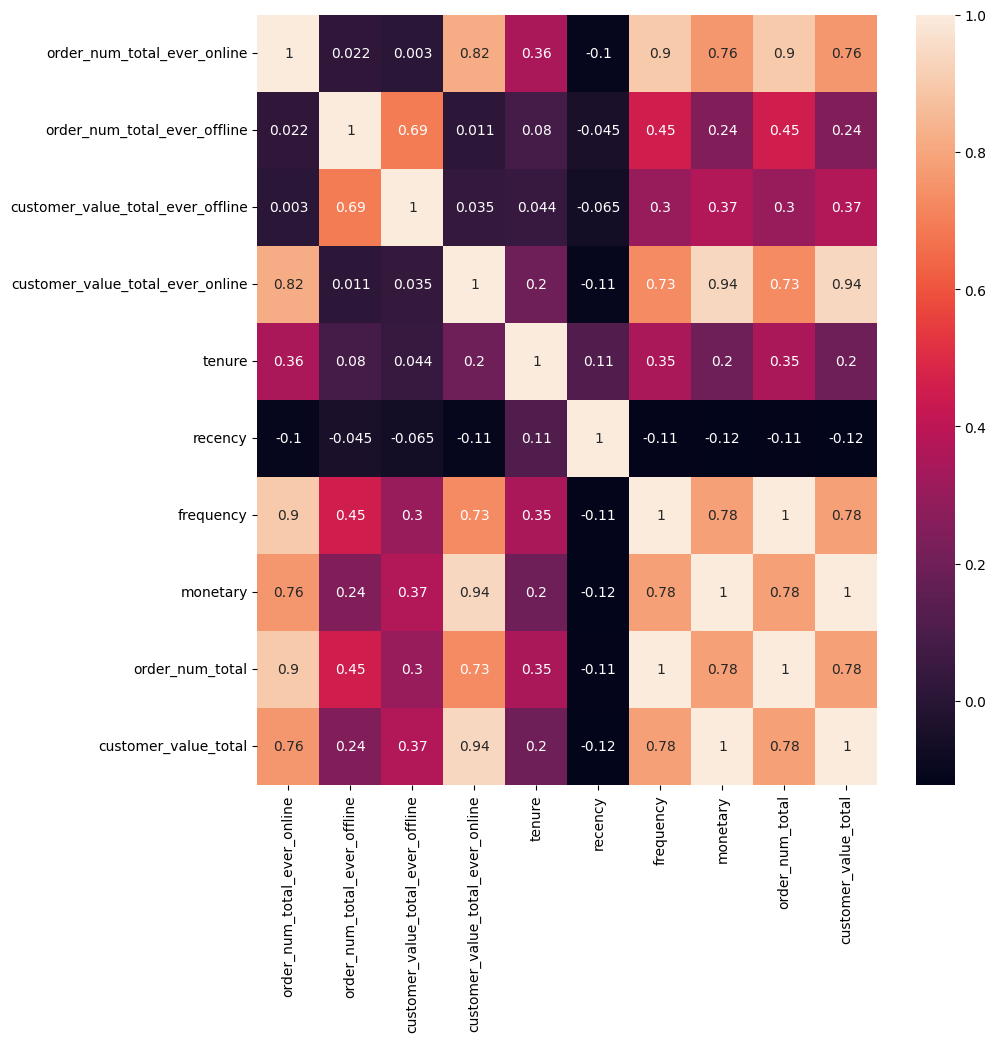

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
corr_matrix=df2[num_cols].corr()
plt.figure(figsize=(10,10))
sns.heatmap(corr_matrix,annot=True)
plt.show()

##**K-Means_Clustering**

In [ ]:
from sklearn.preprocessing import StandardScaler
scaler=StandardScaler()
df2[num_cols]=scaler.fit_transform(df2[num_cols])
df2.head()

,master_id,order_num_total_ever_online,order_num_total_ever_offline,customer_value_total_ever_offline,customer_value_total_ever_online,interested_in_categories_12,tenure,recency,frequency,monetary,...,customer_value_total,order_channel_Android App,order_channel_Desktop,order_channel_Ios App,order_channel_Mobile,last_order_channel_Android App,last_order_channel_Desktop,last_order_channel_Ios App,last_order_channel_Mobile,last_order_channel_Offline
0,1,0.210422,-0.443039,-0.377854,0.362797,[KADIN],-1.122127,-0.382058,-0.005222,0.210107,...,0.210107,1,0,0,0,0,0,0,0,1
1,2,3.760263,0.041732,-0.311591,1.628981,"[ERKEK, COCUK, KADIN, AKTIFSPOR]",1.476349,-0.285232,3.368463,1.409799,...,1.409799,1,0,0,0,0,0,0,1,0
2,3,-0.026234,0.041732,-0.212097,-0.122477,"[ERKEK, KADIN]",-0.476329,0.499055,-0.005222,-0.185312,...,-0.185312,1,0,0,0,1,0,0,0,0
3,4,-0.499547,-0.443039,-0.709501,-0.498860,"[AKTIFCOCUK, COCUK]",-1.252050,0.005244,-0.637788,-0.702802,...,-0.702802,1,0,0,0,1,0,0,0,0
4,5,-0.499547,-0.443039,-0.676337,-0.405164,[AKTIFSPOR],-0.254694,-0.469201,-0.637788,-0.604508,...,-0.604508,0,1,0,0,0,1,0,0,0


In [ ]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
import matplotlib.pyplot as plt
df2.columns

Index(['master_id', 'order_num_total_ever_online',
       'order_num_total_ever_offline', 'customer_value_total_ever_offline',
       'customer_value_total_ever_online', 'interested_in_categories_12',
       'tenure', 'recency', 'frequency', 'monetary', 'order_num_total',
       'customer_value_total', 'order_channel_Android App',
       'order_channel_Desktop', 'order_channel_Ios App',
       'order_channel_Mobile', 'last_order_channel_Android App',
       'last_order_channel_Desktop', 'last_order_channel_Ios App',
       'last_order_channel_Mobile', 'last_order_channel_Offline'],
      dtype='object')

In [ ]:
df3=df2.drop(columns=['master_id','interested_in_categories_12','order_channel_Android App',
       'order_channel_Desktop', 'order_channel_Ios App',
       'order_channel_Mobile', 'last_order_channel_Android App',
       'last_order_channel_Desktop', 'last_order_channel_Ios App',
       'last_order_channel_Mobile', 'last_order_channel_Offline'])

In [ ]:
df3.head()

,order_num_total_ever_online,order_num_total_ever_offline,customer_value_total_ever_offline,customer_value_total_ever_online,tenure,recency,frequency,monetary,order_num_total,customer_value_total
0,0.210422,-0.443039,-0.377854,0.362797,-1.122127,-0.382058,-0.005222,0.210107,-0.005222,0.210107
1,3.760263,0.041732,-0.311591,1.628981,1.476349,-0.285232,3.368463,1.409799,3.368463,1.409799
2,-0.026234,0.041732,-0.212097,-0.122477,-0.476329,0.499055,-0.005222,-0.185312,-0.005222,-0.185312
3,-0.499547,-0.443039,-0.709501,-0.498860,-1.252050,0.005244,-0.637788,-0.702802,-0.637788,-0.702802
4,-0.499547,-0.443039,-0.676337,-0.405164,-0.254694,-0.469201,-0.637788,-0.604508,-0.637788,-0.604508


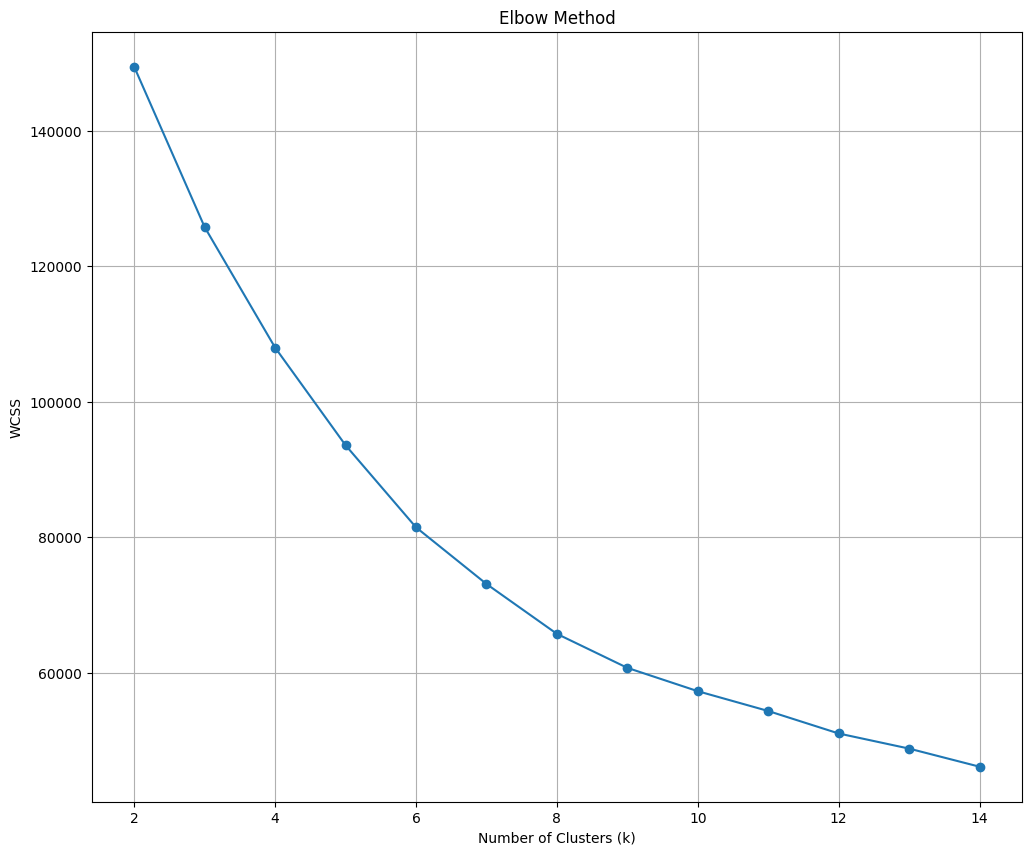

In [ ]:
wcss = []
for k in range(2, 15):
    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        random_state=42,
        n_init=10
    )
    kmeans.fit(df3)
    wcss.append(kmeans.inertia_)

plt.figure(figsize=(12,10))
plt.plot(range(2,15), wcss, marker='o')
plt.xlabel("Number of Clusters (k)")
plt.ylabel("WCSS")
plt.title("Elbow Method")
plt.grid(True)
plt.show()

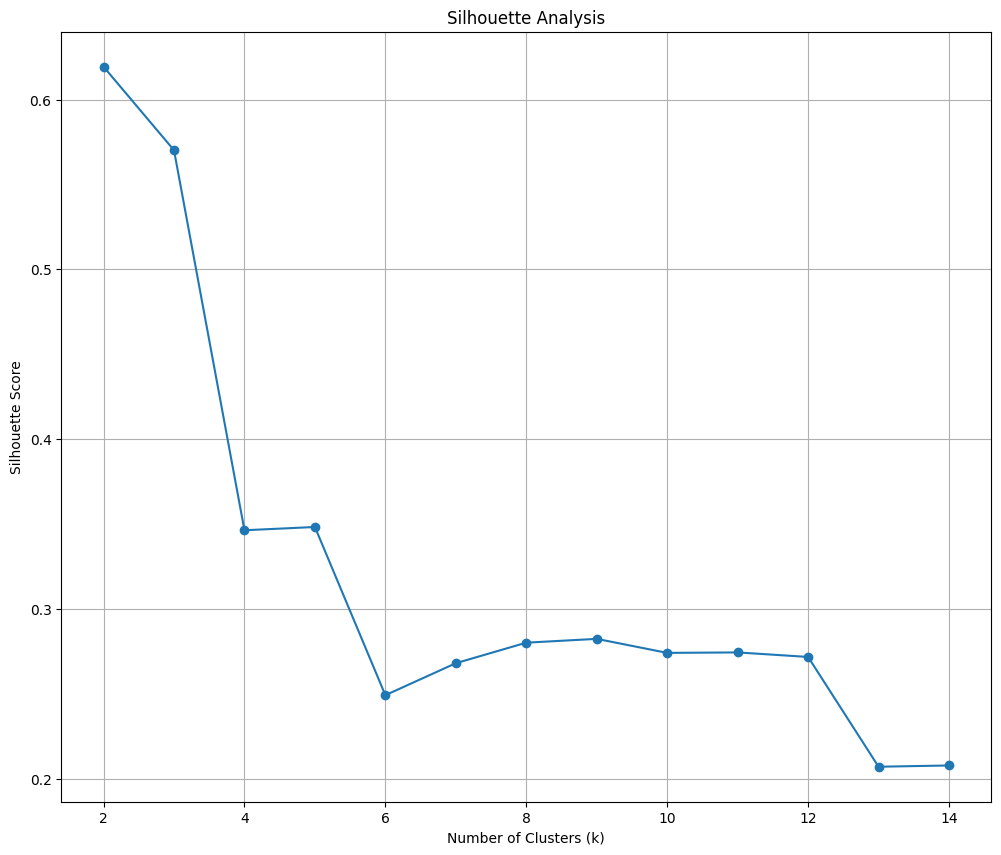

In [ ]:
sil_scores = []

for k in range(2,15):
    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(df3)

    score = silhouette_score(df3, labels)
    sil_scores.append(score)

plt.figure(figsize=(12,10))
plt.plot(range(2,15), sil_scores, marker='o')
plt.xlabel("Number of Clusters (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Analysis")
plt.grid(True)
plt.show()

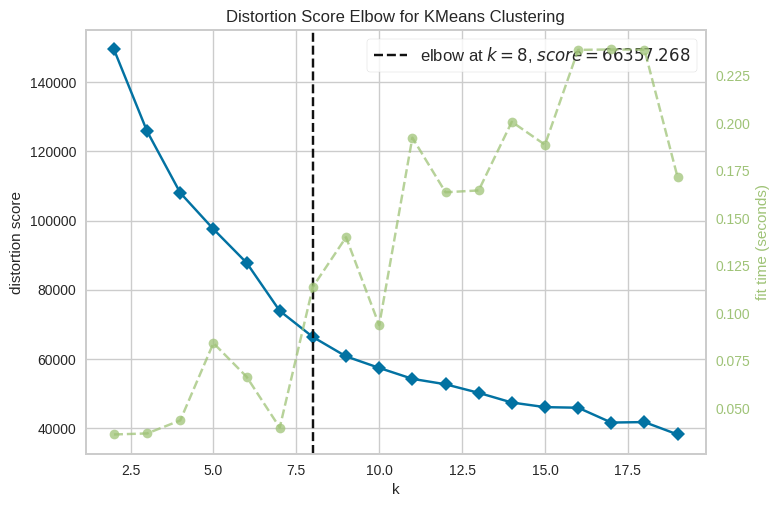

8


In [ ]:
from yellowbrick.cluster import KElbowVisualizer
kmeans = KMeans()
elbow = KElbowVisualizer(kmeans, k=(2, 20))
elbow.fit(df3)
elbow.show()

print(elbow.elbow_value_)

In [ ]:
kmeans = KMeans(n_clusters=elbow.elbow_value_, init='k-means++').fit(df3)
kmeans.cluster_centers_

array([[ 0.06286626, -0.04400355, -0.06166504, -0.12559778,  2.29040601,
         0.29450778,  0.03687273, -0.13755493,  0.03687273, -0.13755493],
       [ 4.23594165,  0.29866115,  0.23379242,  3.41211421,  1.45900527,
        -0.42115092,  3.90403544,  3.25153201,  3.90403544,  3.25153201],
       [-0.144494  ,  1.41043228,  1.70166902, -0.09353945, -0.04374898,
        -0.30229851,  0.4847384 ,  0.48606984,  0.4847384 ,  0.48606984],
       [20.32618901, -0.16602674,  0.860791  , 32.33279837,  1.6305654 ,
        -0.8910832 , 18.03796981, 30.3549695 , 18.03796981, 30.3549695 ],
       [ 0.04658278, 25.28712872, 18.67014342,  0.3528747 , -0.03952635,
         0.07078788, 11.04035317,  6.6154248 , 11.04035317,  6.6154248 ],
       [-0.27788912, -0.18760559, -0.19784091, -0.22214524, -0.4431309 ,
        -0.63826547, -0.32919368, -0.27318906, -0.32919368, -0.27318906],
       [-0.31287918, -0.19630911, -0.23089883, -0.2556799 , -0.24876699,
         1.17393801, -0.36415472, -0.31550421

In [ ]:
kmeans.n_clusters

np.int64(8)

In [ ]:
kmeans.labels_

array([5, 1, 6, ..., 5, 2, 6], dtype=int32)

In [ ]:
kmeans.inertia_ #Displays WCSS value

65754.9244352224

In [ ]:
kmeans.get_params()  # With get_params() we can see the parameters of the kmeans model.

{'algorithm': 'lloyd',
 'copy_x': True,
 'init': 'k-means++',
 'max_iter': 300,
 'n_clusters': np.int64(8),
 'n_init': 'auto',
 'random_state': None,
 'tol': 0.0001,
 'verbose': 0}

##**Build your model and segment your customers.**

In [ ]:
clusters_kmeans = kmeans.labels_    # Indicates which observation the clusters belong to.
df3["cluster"] = clusters_kmeans   # We added a variable named cluster_no to X.
df3.head()

,order_num_total_ever_online,order_num_total_ever_offline,customer_value_total_ever_offline,customer_value_total_ever_online,tenure,recency,frequency,monetary,order_num_total,customer_value_total,cluster
0,0.210422,-0.443039,-0.377854,0.362797,-1.122127,-0.382058,-0.005222,0.210107,-0.005222,0.210107,5
1,3.760263,0.041732,-0.311591,1.628981,1.476349,-0.285232,3.368463,1.409799,3.368463,1.409799,1
2,-0.026234,0.041732,-0.212097,-0.122477,-0.476329,0.499055,-0.005222,-0.185312,-0.005222,-0.185312,6
3,-0.499547,-0.443039,-0.709501,-0.498860,-1.252050,0.005244,-0.637788,-0.702802,-0.637788,-0.702802,5
4,-0.499547,-0.443039,-0.676337,-0.405164,-0.254694,-0.469201,-0.637788,-0.604508,-0.637788,-0.604508,5


In [ ]:
df3["cluster"]=df3["cluster"]+1

In [ ]:
df3["cluster"].value_counts()

,count
cluster,
6,8696
7,5473
8,1968
3,1720
1,1668
2,400
5,13
4,7


In [ ]:
df3["cluster"].value_counts()/len(df3)*100

,count
cluster,
6,43.599900
7,27.440461
8,9.867135
3,8.623715
1,8.362998
2,2.005515
5,0.065179
4,0.035097


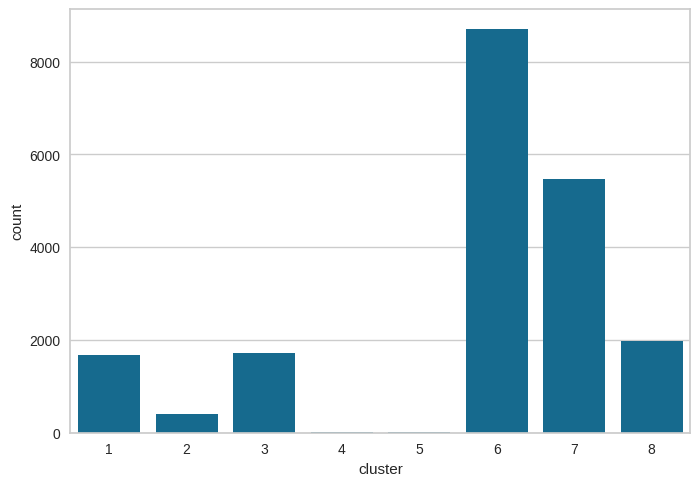

In [ ]:
sns.countplot(x='cluster', data=df3)
plt.show()

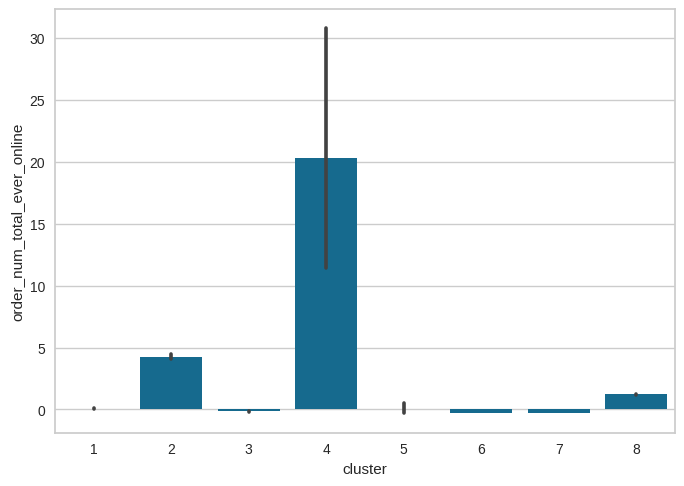

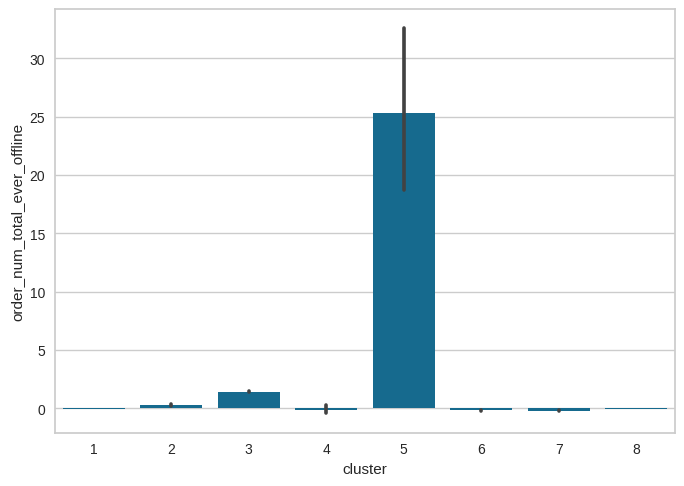

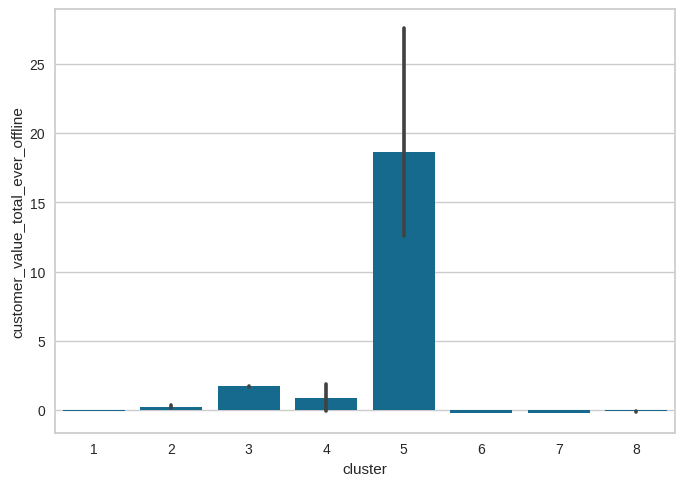

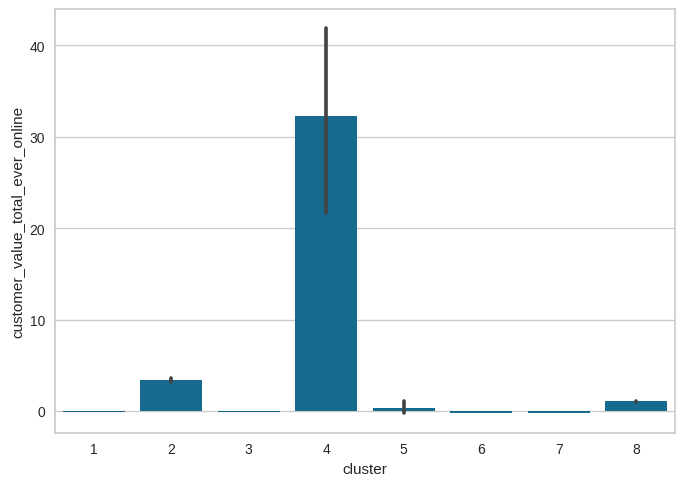

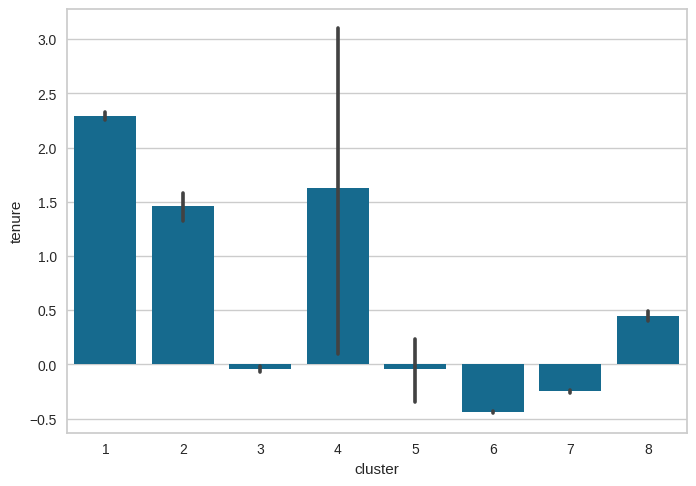

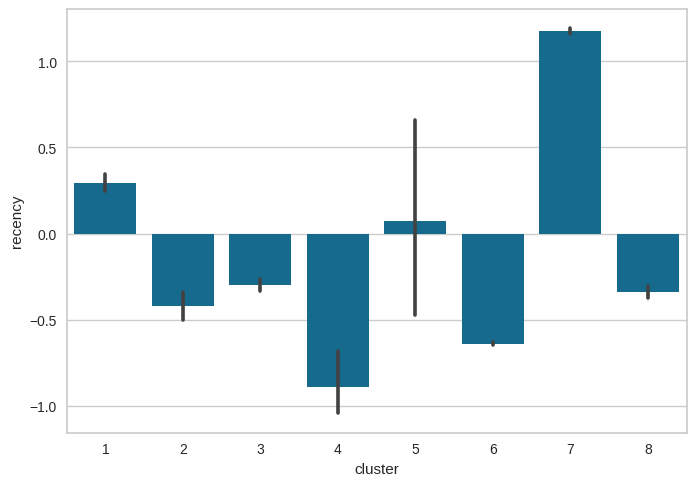

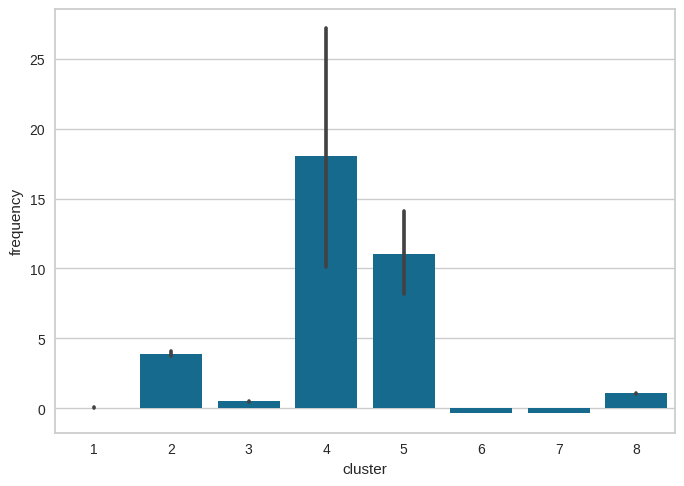

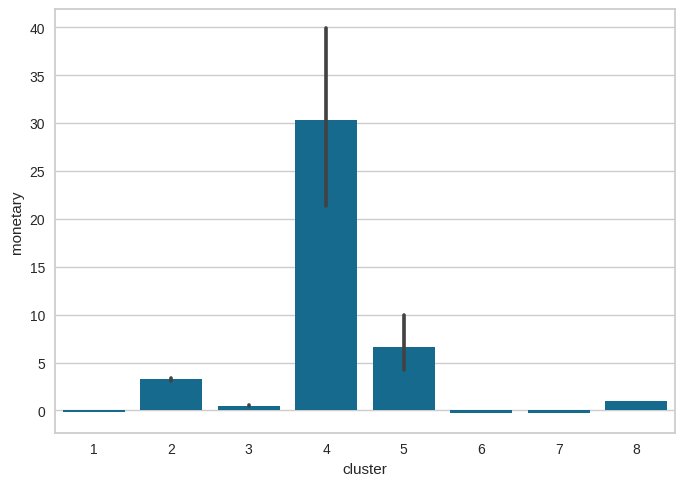

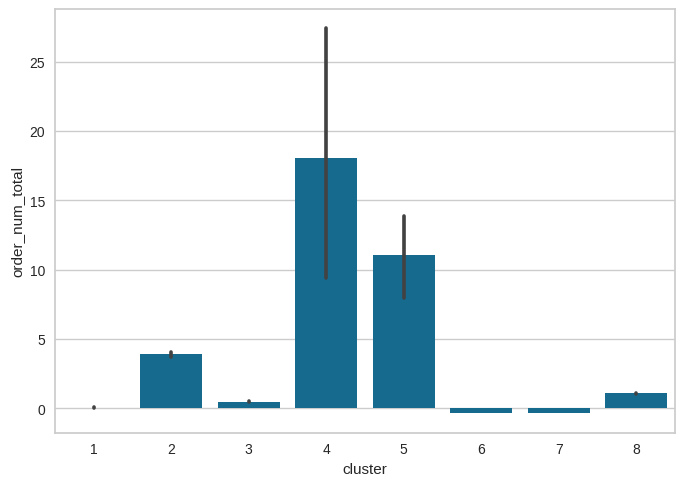

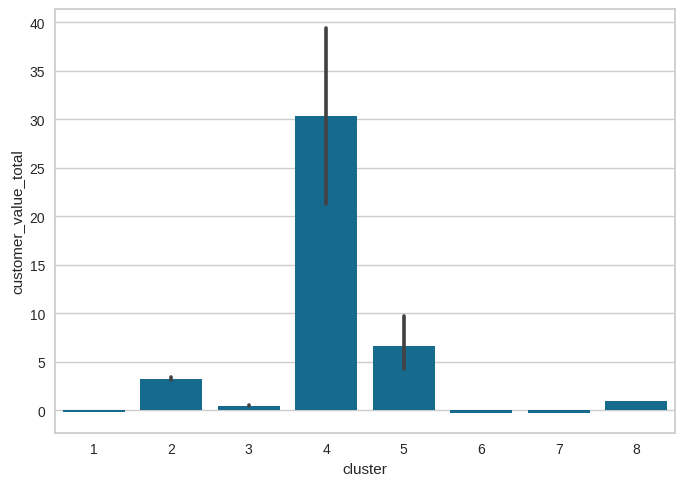

In [ ]:
for i in num_cols:
    sns.barplot(x='cluster', y=i, data=df3)
    plt.show()

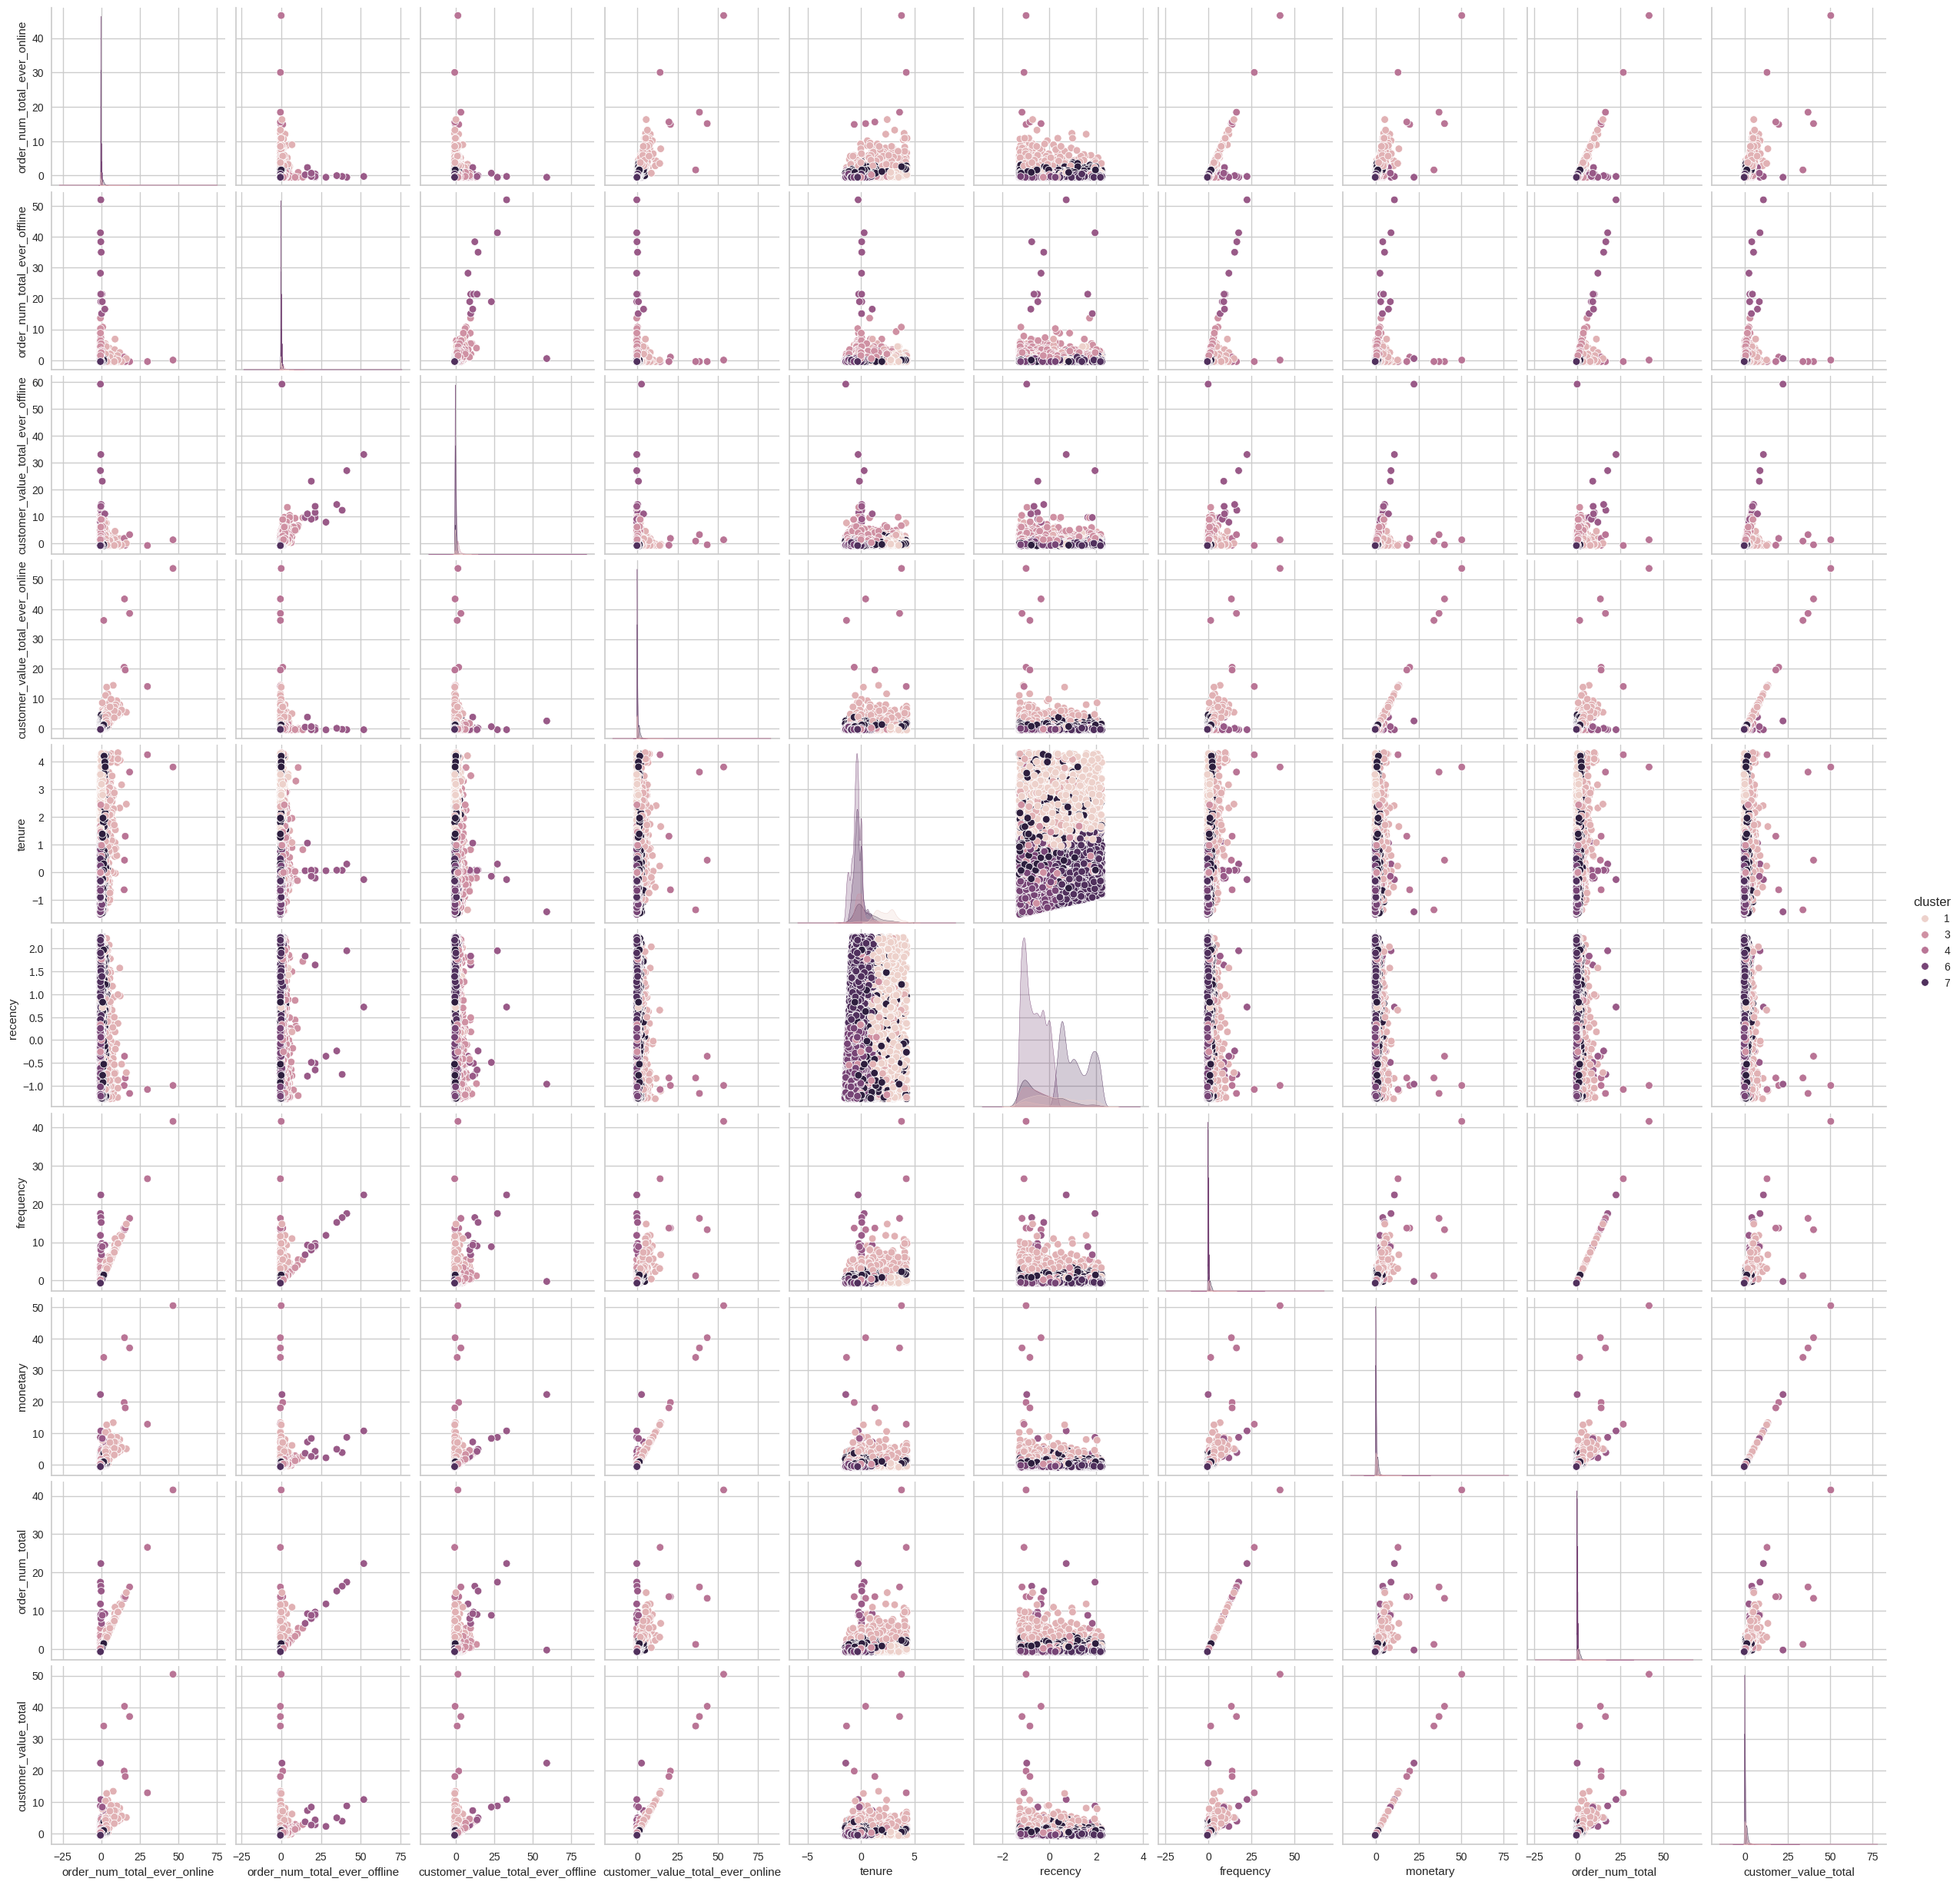

In [ ]:
sns.pairplot(df3, hue='cluster')
plt.show()